# Quality assessment of OAQ Airnet sensors

This notebook checks the 15-minute readings (January to September 2026) of Airnet's low-cost PM2.5 sensors in Bengaluru, as published by [OAQ](https://oaq.notf.in):

1. Completeness: how many of the expected readings arrive.
2. Plausibility: negative, zero, extreme and stuck readings, and readings with spikes.
3. Precision: agreement between the sensors that OAQ lists at one place, the CSTEP Test Bed.
4. Accuracy: agreement with the nearest CPCB reference station, from CPCB's official data.
5. Humidity: whether the sensor-to-reference ratio depends on relative humidity.

The targets (`EPA_PM25_TARGETS`) are from the US EPA's *Performance Testing Protocols, Metrics, and Target Values for Fine Particulate Matter Air Sensors* (Duvall et al., 2021, EPA/600/R-20/280). The EPA protocol puts sensors next to the reference monitor. In this notebook, the nearest CPCB station is up to 3 km away. Thus, the accuracy numbers mix sensor error with real differences between places. Read them as an upper bound on the sensor error.

OAQ's daily records are often the last reading of the day, not its mean (notebook *OAQ low-cost sensors vs the nearest CPCB station*). Thus, every daily value in this notebook is a mean of 15-minute readings (`readings_mean`). The same functions are in the R package. The OAQ calls need `OAQ_API_KEY`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import (
    EPA_PM25_TARGETS,
    CPCBHistorical,
    OAQClient,
    collocated_precision,
    oaq_nearest_cpcb,
    peer_ratio,
    ratio_by_humidity,
    readings_mean,
    sensor_accuracy,
    sensor_completeness,
    sensor_plausibility,
)

pd.set_option("display.width", 160)
oaq = OAQClient()
cpcb = CPCBHistorical()
START, END = "2026-01-01", "2026-09-30"
EPA_PM25_TARGETS

{'completeness': 0.75,
 'sd': 5.0,
 'cv_pct': 30.0,
 'slope': (0.65, 1.35),
 'intercept': (-5.0, 5.0),
 'r2': 0.7,
 'rmse': 7.0,
 'nrmse_pct': 30.0}

## The sensors and their readings

In [2]:
sensors = oaq.sensors(["airnet"])
sites = sensors.groupby(["lat", "lon"]).agg(
    sensors=("id", "size"), name=("name", "first")
)
print(f"{len(sensors)} Airnet sensors at {len(sites)} places")
sites[sites.sensors > 1]

47 Airnet sensors at 28 places


,,sensors,name
lat,lon,,
12.814517,77.705516,2,Tranquil City
13.035533,77.534676,2,Yeshwantpur Stage 1
13.048451,77.579592,18,CSTEP Test Bed


In [3]:
readings = oaq.readings("airnet", sensors["id"], pd.date_range(START, END))
readings = readings[["sensor_id", "timestamp", "pm25"]]
print(f"{len(readings):,} readings of {readings.sensor_id.nunique()} sensors")

482,490 readings of 47 sensors


## 1. Completeness

Readings with a PM2.5 value, out of 96 a day, and the days with a valid 24-hour average (75 % of the readings).

In [4]:
completeness = sensor_completeness(readings, START, END, ids=sensors["id"])
completeness = completeness.merge(
    sensors[["id", "name"]], left_on="sensor_id", right_on="id"
).drop(columns="id")
print(
    f"Sensors with a valid 24-hour average on at least 75 % of the days: "
    f"{(completeness.valid_days_pct >= 75).sum()} of {len(completeness)}"
)
completeness[["readings_pct", "valid_days_pct"]].describe().round(1)

Sensors with a valid 24-hour average on at least 75 % of the days: 0 of 47


,readings_pct,valid_days_pct
count,47.0,47.0
mean,35.9,23.5
std,25.4,26.2
min,0.0,0.0
25%,11.6,0.4
50%,39.6,13.6
75%,57.6,45.1
max,73.8,72.2


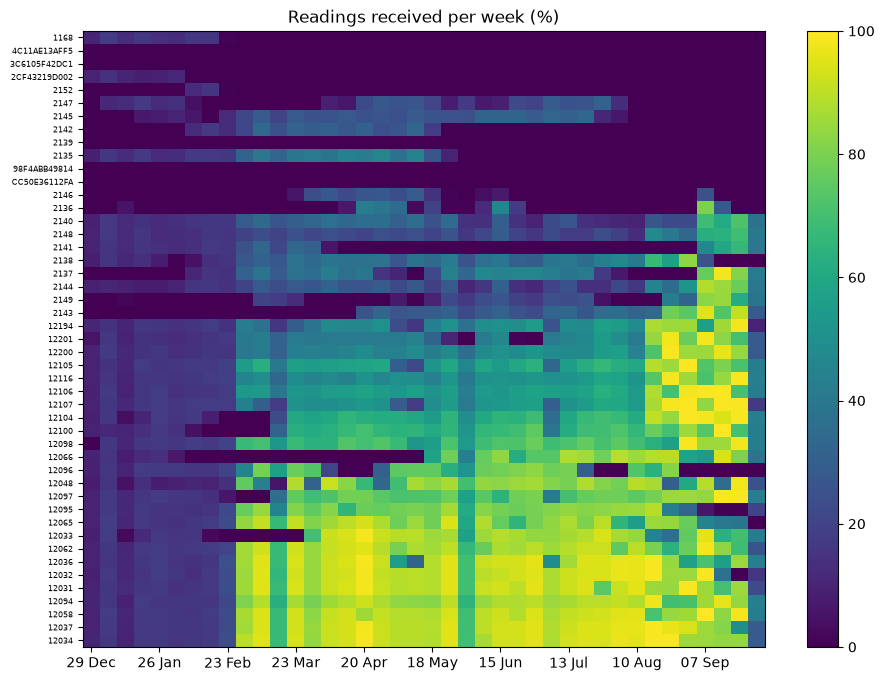

In [5]:
weekly = readings.dropna(subset=["pm25"]).assign(
    week=lambda d: d.timestamp.dt.to_period("W").dt.start_time
)
grid = weekly.pivot_table(
    index="sensor_id", columns="week", values="pm25", aggfunc="size", fill_value=0
)
grid = (
    (100 * grid / (7 * 96))
    .reindex(completeness.sort_values("valid_days_pct").sensor_id)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(grid.values, aspect="auto", cmap="viridis", vmin=0, vmax=100)
ax.set_yticks(range(len(grid)), grid.index, fontsize=6)
ax.set_xticks(
    range(0, grid.shape[1], 4), [w.strftime("%d %b") for w in grid.columns[::4]]
)
ax.set_title("Readings received per week (%)")
fig.colorbar(im, ax=ax)
plt.show()

## 2. Plausibility

`sensor_plausibility` flags these readings:

- negative readings
- readings of exactly 0
- readings above 1000 µg/m³
- readings inside a *stuck* run (the same value 8 or more times in a row, 2 hours)
- *spikes*: readings above 10 times the median of the 2 hours around them and above 100 µg/m³.

These are plausibility rules, not EPA targets.

In [6]:
plausibility = sensor_plausibility(readings)
plausibility.describe().round(3)

,readings,negative_pct,zero_pct,above_max_pct,stuck_pct,spikes_pct
count,43.000,43.0,43.0,43.0,43.0,43.000
mean,10293.512,0.0,0.0,0.0,0.0,0.002
std,6258.165,0.0,0.0,0.0,0.0,0.006
min,1.000,0.0,0.0,0.0,0.0,0.000
25%,4214.000,0.0,0.0,0.0,0.0,0.000
50%,11076.000,0.0,0.0,0.0,0.0,0.000
75%,15181.500,0.0,0.0,0.0,0.0,0.000
max,19331.000,0.0,0.0,0.0,0.0,0.026


In [7]:
flags = ["negative_pct", "zero_pct", "above_max_pct", "stuck_pct", "spikes_pct"]
plausibility[(plausibility[flags] > 1).any(axis=1)].round(2)

,sensor_id,readings,negative_pct,zero_pct,above_max_pct,stuck_pct,spikes_pct


## 3. Precision at the CSTEP Test Bed

The CSTEP Test Bed has the largest group of sensors that OAQ lists at the same coordinates. For each day with a valid mean from at least 3 of these sensors, `collocated_precision` gives the SD and CV across the sensors.

In [8]:
daily = readings_mean(readings)
bed_place = sites.sensors.idxmax()
bed = sensors.set_index(["lat", "lon"]).loc[[bed_place], "id"].tolist()
precision = collocated_precision(daily[daily.sensor_id.isin(bed)])
print(
    f"{sites.loc[bed_place, 'name']}: {len(bed)} sensors, {len(precision)} days with 3 or more valid sensors"
)
pd.DataFrame(
    {
        "median": precision[["sd", "cv_pct"]].median(),
        "days meeting the target (%)": [
            100 * (precision.sd <= EPA_PM25_TARGETS["sd"]).mean(),
            100 * (precision.cv_pct <= EPA_PM25_TARGETS["cv_pct"]).mean(),
        ],
        "EPA target": [EPA_PM25_TARGETS["sd"], EPA_PM25_TARGETS["cv_pct"]],
    }
).round(1)

CSTEP Test Bed: 18 sensors, 65 days with 3 or more valid sensors


,median,days meeting the target (%),EPA target
sd,6.1,24.6,5.0
cv_pct,26.3,70.8,30.0


This section shows which sensors differ from the others. `peer_ratio` gives the median ratio of each sensor to the median of the others on the same day. It also gives the share of days within ±30 %.

In [9]:
peers = peer_ratio(daily[daily.sensor_id.isin(bed)])
peers.round(2)

,sensor_id,days,median_ratio,within_pct
0,2149,24,0.63,33.33
1,2143,31,0.65,38.71
2,12107,40,0.89,100.00
3,12036,55,0.91,100.00
4,12104,46,0.93,95.65
5,2137,21,0.99,100.00
6,12100,55,1.06,63.64
7,12105,38,1.07,100.00
8,12194,34,1.09,94.12
9,12097,61,1.44,29.51


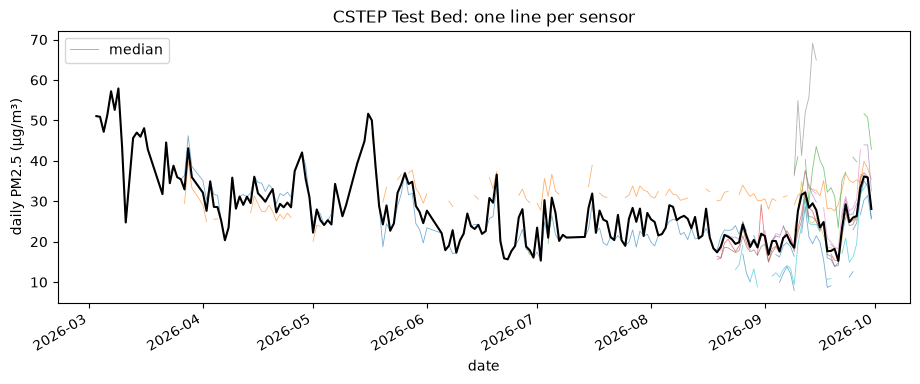

In [10]:
wide = daily[daily.sensor_id.isin(bed)].pivot(
    index="date", columns="sensor_id", values="pm25"
)
wide.index = pd.to_datetime(wide.index)
ax = wide.plot(figsize=(11, 4), lw=0.6, alpha=0.6, legend=False)
wide.median(axis=1).plot(ax=ax, color="k", lw=1.5, label="median of the sensors")
ax.set_ylabel("daily PM2.5 (µg/m³)")
ax.set_title("CSTEP Test Bed: one line per sensor")
ax.legend(["median"])
plt.show()

## 4. Accuracy against the nearest CPCB station

The reference data are CPCB's official 15-minute data (`CPCBHistorical.raw_readings`) at the nearest CPCB station within 3 km of each sensor. The notebook averages them in the same way. `sensor_accuracy` fits *sensor = intercept + slope × CPCB* for sensors with at least 30 paired days. It reports R², RMSE, NRMSE and the EPA targets that each sensor meets.

In [11]:
pairs = oaq_nearest_cpcb(sensors, k=1).query("distance_km <= 3")
raw = cpcb.raw_readings(
    pairs.cpcb_station_id.unique(), 2026, pollutants=["PM2.5", "RH"]
)
reference = readings_mean(
    raw[raw.pollutant == "PM2.5"], value="value", id_col="station_id"
)
paired = daily.merge(
    pairs[["sensor_id", "cpcb_station_id", "distance_km"]], on="sensor_id"
).merge(
    reference.rename(columns={"station_id": "cpcb_station_id", "value": "reference"}),
    on=["cpcb_station_id", "date"],
)
print(
    f"{len(paired)} sensor-days of {paired.sensor_id.nunique()} sensors; "
    f"CPCB stations with data: {sorted(reference.station_id.unique())}"
)

SSL verification failed for airquality.cpcb.gov.in; sending without verification


770 sensor-days of 15 sensors; CPCB stations with data: ['site_1553', 'site_1554', 'site_162', 'site_164', 'site_5681', 'site_5729']


In [12]:
accuracy = sensor_accuracy(paired)
accuracy = accuracy.merge(
    pairs[["sensor_id", "cpcb_station_name", "distance_km"]], on="sensor_id"
)
accuracy["test bed"] = accuracy.sensor_id.isin(bed)
targets = ["slope_ok", "intercept_ok", "r2_ok", "error_ok"]
print(
    "Sensors meeting each target:",
    accuracy[targets].sum().to_dict(),
    f"of {len(accuracy)}",
)
accuracy.drop(columns=targets).sort_values("r2").round(2)

Sensors meeting each target: {'slope_ok': 7, 'intercept_ok': 1, 'r2_ok': 2, 'error_ok': 1} of 11


,sensor_id,days,slope,intercept,r2,rmse,nrmse_pct,targets_met,cpcb_station_name,distance_km,test bed
5,12097,100,-0.05,32.48,0.02,18.68,92.85,0,"Hebbal, Bengaluru - KSPCB",2.25,True
1,12048,63,0.20,14.76,0.07,23.41,65.75,0,"BWSSB Kadabesanahalli, Bengaluru - CPCB",0.54,False
3,12094,38,-0.59,44.54,0.16,19.18,51.09,0,"Kasturi Nagar, Bengaluru - KSPCB",2.79,False
7,12104,41,0.73,11.82,0.44,9.06,59.84,1,"Hebbal, Bengaluru - KSPCB",2.25,True
2,12065,101,1.32,-12.35,0.48,13.15,41.15,1,"Jigani, Bengaluru - KSPCB",1.85,False
6,12100,45,0.89,15.96,0.49,16.15,99.31,1,"Hebbal, Bengaluru - KSPCB",2.25,True
4,12096,71,0.81,-0.40,0.61,8.57,37.06,2,"Bapuji Nagar, Bengaluru - KSPCB",0.14,False
10,12194,30,1.23,6.81,0.65,10.74,74.23,1,"Hebbal, Bengaluru - KSPCB",2.25,True
9,12107,36,0.90,7.23,0.68,6.43,41.85,2,"Hebbal, Bengaluru - KSPCB",2.25,True
8,12105,33,1.18,7.21,0.74,10.59,68.05,2,"Hebbal, Bengaluru - KSPCB",2.25,True


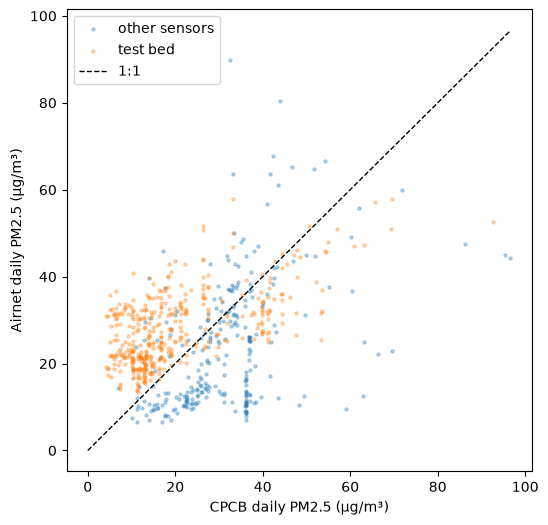

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
shown = paired[paired.sensor_id.isin(accuracy.sensor_id)]
for label, g in shown.groupby(
    shown.sensor_id.isin(bed).map({True: "test bed", False: "other sensors"})
):
    ax.scatter(g.reference, g.pm25, s=5, alpha=0.3, label=label)
top = shown[["reference", "pm25"]].max().max()
ax.plot([0, top], [0, top], "k--", lw=1, label="1:1")
ax.set_xlabel("CPCB daily PM2.5 (µg/m³)")
ax.set_ylabel("Airnet daily PM2.5 (µg/m³)")
ax.legend()
plt.show()

## 5. Relative humidity

Optical sensors can give high readings in humid air, when particles absorb water. `ratio_by_humidity` compares hourly medians of the test-bed sensors with the CPCB station nearest to the test bed. That station also measures relative humidity.

In [14]:
station = pairs.loc[pairs.sensor_id.isin(bed), "cpcb_station_id"].mode()[0]
cpcb_hourly = {
    p: readings_mean(
        raw[(raw.station_id == station) & (raw.pollutant == p)],
        value="value",
        by="hour",
        id_col="station_id",
    ).set_index("hour")["value"]
    for p in ["PM2.5", "RH"]
}
hourly = pd.DataFrame(
    {
        "sensor": readings_mean(readings[readings.sensor_id.isin(bed)], by="hour")
        .groupby("hour")
        .pm25.median(),
        "reference": cpcb_hourly["PM2.5"],
        "rh": cpcb_hourly["RH"],
    }
).dropna()
print(f"{len(hourly)} hours at {station}")
ratio_by_humidity(hourly).round(2)

3507 hours at site_1554


,band,hours,median_ratio,q25,q75
0,0-40,58,1.14,1.07,1.26
1,40-50,334,1.46,1.14,2.04
2,50-60,663,1.71,1.22,2.65
3,60-70,1002,1.65,1.02,2.33
4,70-80,513,0.89,0.74,1.41
5,80-90,383,0.84,0.69,1.07
6,90-100,213,0.92,0.76,1.14


## Scorecard

The scorecard has one row for each sensor. A new run of the notebook updates every number.

In [15]:
score = (
    completeness[["sensor_id", "name", "valid_days_pct"]]
    .merge(
        plausibility.assign(flagged_pct=plausibility[flags].sum(axis=1))[
            ["sensor_id", "flagged_pct"]
        ],
        on="sensor_id",
        how="left",
    )
    .merge(
        peers[["sensor_id", "median_ratio"]].rename(
            columns={"median_ratio": "ratio_to_peers"}
        ),
        on="sensor_id",
        how="left",
    )
    .merge(
        accuracy[["sensor_id", "r2", "slope", "rmse", "targets_met"]],
        on="sensor_id",
        how="left",
    )
)
score.sort_values("valid_days_pct", ascending=False).round(2)

,sensor_id,name,valid_days_pct,flagged_pct,ratio_to_peers,r2,slope,rmse,targets_met
4,12034,Rachenahalli,72.16,0.00,NaN,NaN,NaN,NaN,NaN
6,12037,Attur Layout,71.43,0.03,NaN,NaN,NaN,NaN,NaN
8,12058,Yeshwantpur Stage 1,70.70,0.00,NaN,NaN,NaN,NaN,NaN
12,12094,Mahadevapura,70.33,0.00,NaN,0.16,-0.59,19.18,0.0
1,12031,Rajanukunte,69.60,0.00,NaN,NaN,NaN,NaN,NaN
2,12032,Kumarapark west,68.13,0.00,NaN,NaN,NaN,NaN,NaN
5,12036,CSTEP Test Bed,66.67,0.00,0.91,0.76,0.47,11.15,1.0
9,12062,Shakti Layout,65.93,0.00,NaN,NaN,NaN,NaN,NaN
3,12033,Tranquil City,55.68,0.01,NaN,NaN,NaN,NaN,NaN
10,12065,Jigani Industrial Area-2,53.48,0.01,NaN,0.48,1.32,13.15,1.0


## Notes

- The plausibility rules are specific to this package. They do not come from the EPA protocol.
- The accuracy check uses a CPCB station up to 3 km away, not a collocated monitor. Thus, the accuracy includes real differences between places.
- The notebook uses OAQ's coordinates for the location of each sensor. It treats sensors that share coordinates as collocated. OAQ's coordinates are the only location data available.